In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to C:\Users\Sonu
[nltk_data]     Kumar\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [2]:
df = pd.read_csv('spam.csv', encoding='latin-1')

df = df[['v1', 'v2']]
df.columns = ['label', 'message']

df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

print("Dataset Shape:", df.shape)
print("\nClass Distribution:")
print(df['label'].value_counts())
df.head()

Dataset Shape: (5572, 3)

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [3]:
ps = PorterStemmer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()
    
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'<.*?>', '', text)
    
    text = re.sub(r'[%s]' % re.escape(string.punctuation), ' ', text)
    text = re.sub(r'\d+', ' ', text)
    
    words = text.split()
    words = [ps.stem(word) for word in words if word not in stop_words and len(word) > 2]
    
    return ' '.join(words)

df['cleaned_message'] = df['message'].apply(clean_text)
df[['message', 'cleaned_message']].head()

,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...",jurong point crazi avail bugi great world buff...
1,Ok lar... Joking wif u oni...,lar joke wif oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win cup final tkt may tex...
3,U dun say so early hor... U c already then say...,dun say earli hor alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


In [4]:
X = df['cleaned_message']
y = df['label_num']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# TF-IDF Vectorizer
tfidf = TfidfVectorizer(max_features=4000, ngram_range=(1, 2))

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"Feature Space Dimensions: {X_train_tfidf.shape[1]} features")

Feature Space Dimensions: 4000 features


In [5]:
# 1. Linear SVM
linear_svm = LinearSVC(C=1.0, random_state=42)
linear_svm.fit(X_train_tfidf, y_train)

# 2. RBF Kernel SVM
rbf_svm = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
rbf_svm.fit(X_train_tfidf, y_train)

# Predictions
y_pred_linear = linear_svm.predict(X_test_tfidf)
y_pred_rbf = rbf_svm.predict(X_test_tfidf)

In [6]:
def get_metrics(y_true, y_pred, model_name):
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (Spam)': precision_score(y_true, y_pred),
        'Recall (Spam)': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred)
    }

results_df = pd.DataFrame([
    get_metrics(y_test, y_pred_linear, 'Linear SVM (LinearSVC)'),
    get_metrics(y_test, y_pred_rbf, 'RBF Kernel SVM (SVC)')
])

print("Model Comparison Summary:")
display(results_df)

print("\n--- Detailed Classification Report (Linear SVM) ---")
print(classification_report(y_test, y_pred_linear, target_names=['Ham', 'Spam']))

Model Comparison Summary:


,Model,Accuracy,Precision (Spam),Recall (Spam),F1-Score
0,Linear SVM (LinearSVC),0.983857,0.978102,0.899329,0.937063
1,RBF Kernel SVM (SVC),0.980269,0.992248,0.859060,0.920863



--- Detailed Classification Report (Linear SVM) ---
              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       966
        Spam       0.98      0.90      0.94       149

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



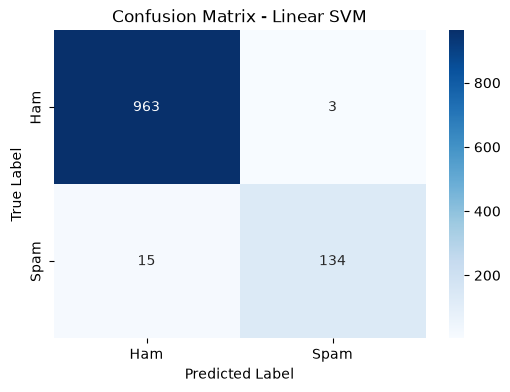

In [7]:
cm = confusion_matrix(y_test, y_pred_linear)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Confusion Matrix - Linear SVM')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [8]:
param_grid = {
    'C': [0.1, 0.5, 1.0, 2.0, 5.0],
    'loss': ['hinge', 'squared_hinge']
}

grid = GridSearchCV(LinearSVC(random_state=42, max_iter=2000), param_grid, cv=5, scoring='f1', n_jobs=-1)
grid.fit(X_train_tfidf, y_train)

print("Best Parameters:", grid.best_params_)
best_model = grid.best_estimator_

# Final Evaluation
final_preds = best_model.predict(X_test_tfidf)
print(f"Optimized Precision: {precision_score(y_test, final_preds):.4f}")
print(f"Optimized Recall: {recall_score(y_test, final_preds):.4f}")

Best Parameters: {'C': 2.0, 'loss': 'hinge'}
Optimized Precision: 0.9716
Optimized Recall: 0.9195


In [9]:
def predict_sms(message):
    cleaned = clean_text(message)
    vectorized = tfidf.transform([cleaned])
    prediction = best_model.predict(vectorized)[0]
    
    result = "SPAM" if prediction == 1 else "HAM (Legitimate)"
    return f"Message: '{message}'\nResult: [{result}]"

# Test samples
print(predict_sms("Hey bro, are we meeting today for college project?"))
print(predict_sms("WINNER!! You have won a cash prize of $1000. Call 9876543210 to claim now."))

Message: 'Hey bro, are we meeting today for college project?'
Result: [HAM (Legitimate)]
Message: 'WINNER!! You have won a cash prize of $1000. Call 9876543210 to claim now.'
Result: [SPAM]


In [12]:
import joblib

joblib.dump(best_model, 'svm_spam_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')
print("Model and vectorizer pickle files successfully saved!")

Model and vectorizer pickle files successfully saved!
